## Simpsons MNIST Perceptron Classification

---

In [28]:
import os
import random
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

np.random.seed(42)
random.seed(42)

# TODO: Set constants and stuff here

### 1. Data Processing

In [29]:
# Mapping from label index to character name
label_map = {
    0: "bart_simpson",
    1: "charles_montgomery_burns",
    2: "homer_simpson",
    3: "krusty_the_clown",
    4: "lisa_simpson",
    5: "marge_simpson",
    6: "milhouse_van_houten",
    7: "moe_szyslak",
    8: "ned_flanders",
    9: "principal_skinner"
}

# Reverse map: name -> index
label_map_inv = {v: k for k, v in label_map.items()}

def load_dataset(base_path, mode="grayscale"):
    """
    Load dataset from data/rgb or data/grayscale.
    mode: "grayscale" or "rgb"
    """
    X, y = [], []
    train_path = os.path.join(base_path, "train")

    for label_name in os.listdir(train_path):
        label_dir = os.path.join(train_path, label_name)
        if not os.path.isdir(label_dir):
            continue
        label = label_map_inv[label_name]

        for file in os.listdir(label_dir):
            img_path = os.path.join(label_dir, file)
            img = Image.open(img_path)
            if mode == "grayscale":
                img = img.convert("L")
            else:
                img = img.convert("RGB")

            arr = np.array(img).flatten().astype(np.float32)
            X.append(arr)
            y.append(label)

    X = np.array(X)
    y = np.array(y)

    return X, y

# Example usage
X_gray, y_gray = load_dataset("data/grayscale", mode="grayscale")
X_rgb, y_rgb = load_dataset("data/rgb", mode="rgb")

# Split into train and validation
X_train_gray, X_val_gray, y_train_gray, y_val_gray = train_test_split(X_gray, y_gray, test_size=0.2, random_state=42)
X_train_rgb, X_val_rgb, y_train_rgb, y_val_rgb = train_test_split(X_rgb, y_rgb, test_size=0.2, random_state=42)

### 2. Perceptron Implementation

In [ ]:
class BinaryPerceptron:
    def __init__(self, n_features, learning_rate=0.01):
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.lr = learning_rate

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

    def update(self, X, y):
        for xi, target in zip(X, y):
            pred = self.predict(xi)
            update = self.lr * (target - pred)
            self.weights += update * xi
            self.bias += update

class MultiClassPerceptron:
    def __init__(self, n_classes, n_features, learning_rate=0.01):
        self.classes = n_classes
        self.models = [BinaryPerceptron(n_features, learning_rate) for _ in range(n_classes)]

    def predict(self, X):
        scores = [np.dot(X, model.weights) + model.bias for model in self.models]
        return np.argmax(scores, axis=0)

    def update(self, X, y):
        for xi, target in zip(X, y):
            for i, model in enumerate(self.models):
                binary_label = 1 if target == i else 0
                pred = model.predict(xi)
                update = model.lr * (binary_label - pred)
                model.weights += update * xi
                model.bias += update

### 3. Training Loop

In [31]:
def train_perceptron(model, X, y, X_val, y_val, epochs=10, stop_criteria="epochs"):
    history = {"train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        # Shuffle data
        indices = np.arange(len(X))
        np.random.shuffle(indices)
        X, y = X[indices], y[indices]

        model.update(X, y)

        # Compute accuracy
        train_acc = np.mean([model.predict(xi) == yi for xi, yi in zip(X, y)])
        val_acc = np.mean([model.predict(xi) == yi for xi, yi in zip(X_val, y_val)])

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{epochs}, Train Acc: {train_acc:.3f}, Val Acc: {val_acc:.3f}")

    return history

### 4. Hyperparameter Tuning (Grid Search Skeleton)

In [32]:
def grid_search(X_train, y_train, X_val, y_val, n_classes, learning_rates=[0.01, 0.1], inits=["zero", "random"]):
    results = []
    for lr in learning_rates:
        for init in inits:
            n_features = X_train.shape[1]
            model = MultiClassPerceptron(n_classes, n_features, learning_rate=lr)

            # Init strategy
            if init == "random":
                for m in model.models:
                    m.weights = np.random.randn(n_features) * 0.01

            history = train_perceptron(model, X_train, y_train, X_val, y_val, epochs=10)
            best_val = max(history["val_acc"])
            results.append((lr, init, best_val))
    return results

### 5. Evaluation

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, X, y):
    preds = [model.predict(xi) for xi in X]
    acc = accuracy_score(y, preds)
    prec = precision_score(y, preds, average=None)
    rec = recall_score(y, preds, average=None)
    f1 = f1_score(y, preds, average=None)
    cm = confusion_matrix(y, preds)

    print("Accuracy:", acc)
    print("Per-class Precision:", prec)
    print("Per-class Recall:", rec)
    print("Per-class F1:", f1)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_map.values(), yticklabels=label_map.values())
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

In [34]:
def load_subset(base_path, mode="grayscale", max_per_class=100):
    X, y = [], []
    train_path = os.path.join(base_path, "train")
    for label_name in os.listdir(train_path):
        label_dir = os.path.join(train_path, label_name)
        if not os.path.isdir(label_dir):
            continue
        label = label_map_inv[label_name]
        files = os.listdir(label_dir)[:max_per_class]
        for file in files:
            img_path = os.path.join(label_dir, file)
            img = Image.open(img_path)
            if mode == "grayscale":
                img = img.convert("L")
            else:
                img = img.convert("RGB")
            arr = np.array(img).flatten().astype(np.float32)
            X.append(arr)
            y.append(label)
    return np.array(X), np.array(y)

# Load small subsets
X_gray, y_gray = load_dataset("data/grayscale", mode="grayscale") # load_subset
X_rgb, y_rgb = load_dataset("data/rgb", mode="rgb")

# Train/val split
X_train_gray, X_val_gray, y_train_gray, y_val_gray = train_test_split(X_gray, y_gray, test_size=0.2, random_state=42)
X_train_rgb, X_val_rgb, y_train_rgb, y_val_rgb = train_test_split(X_rgb, y_rgb, test_size=0.2, random_state=42)

print("Grayscale subset:", X_train_gray.shape, y_train_gray.shape)
print("RGB subset:", X_train_rgb.shape, y_train_rgb.shape)


Grayscale subset: (6400, 784) (6400,)
RGB subset: (6400, 2352) (6400,)


Training grayscale perceptron demo...
Epoch 1/20, Train Acc: 0.156, Val Acc: 0.147
Epoch 2/20, Train Acc: 0.297, Val Acc: 0.207
Epoch 3/20, Train Acc: 0.165, Val Acc: 0.131
Epoch 4/20, Train Acc: 0.241, Val Acc: 0.186
Epoch 5/20, Train Acc: 0.150, Val Acc: 0.116
Epoch 6/20, Train Acc: 0.268, Val Acc: 0.177
Epoch 7/20, Train Acc: 0.315, Val Acc: 0.205
Epoch 8/20, Train Acc: 0.213, Val Acc: 0.144
Epoch 9/20, Train Acc: 0.306, Val Acc: 0.179
Epoch 10/20, Train Acc: 0.271, Val Acc: 0.171
Epoch 11/20, Train Acc: 0.365, Val Acc: 0.216
Epoch 12/20, Train Acc: 0.235, Val Acc: 0.158
Epoch 13/20, Train Acc: 0.230, Val Acc: 0.162
Epoch 14/20, Train Acc: 0.242, Val Acc: 0.162
Epoch 15/20, Train Acc: 0.315, Val Acc: 0.198
Epoch 16/20, Train Acc: 0.121, Val Acc: 0.102
Epoch 17/20, Train Acc: 0.145, Val Acc: 0.119
Epoch 18/20, Train Acc: 0.361, Val Acc: 0.206
Epoch 19/20, Train Acc: 0.341, Val Acc: 0.192
Epoch 20/20, Train Acc: 0.257, Val Acc: 0.145

Validation performance (grayscale subset):
Accurac

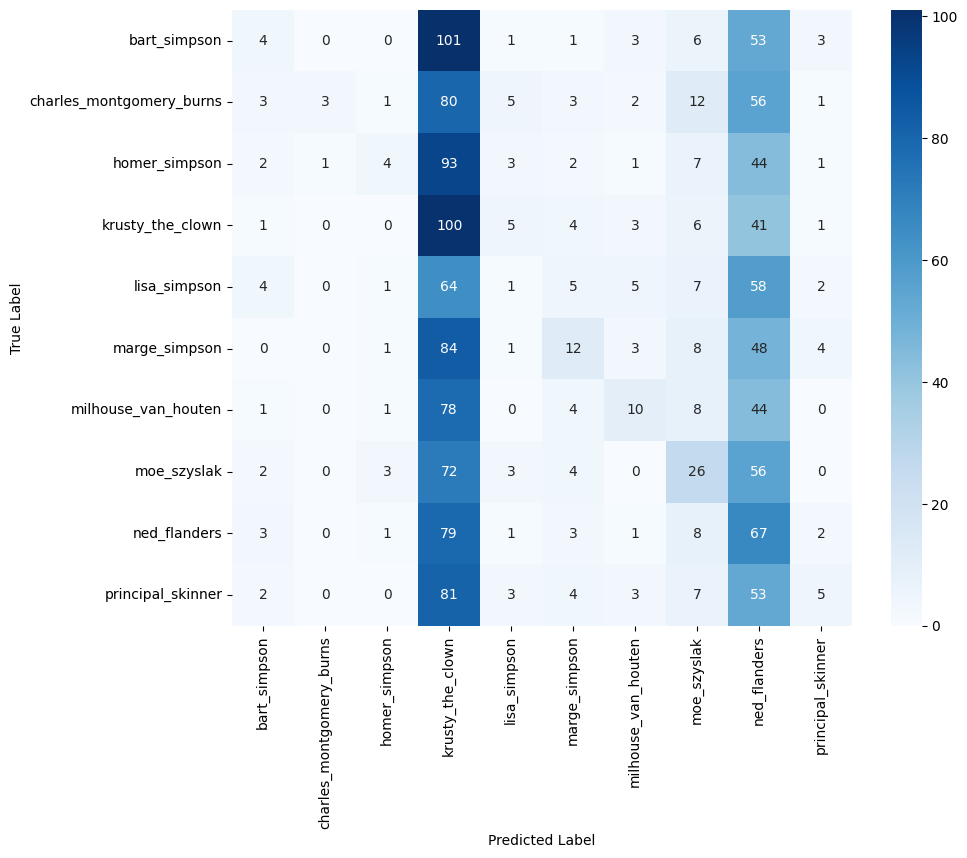

In [35]:
print("Training grayscale perceptron demo...")
n_features = X_train_gray.shape[1]
model_gray = MultiClassPerceptron(n_classes=10, n_features=n_features, learning_rate=0.01)
history_gray = train_perceptron(model_gray, X_train_gray, y_train_gray, X_val_gray, y_val_gray, epochs=20) # epochs = 5

print("\nValidation performance (grayscale subset):")
evaluate_model(model_gray, X_val_gray, y_val_gray)


Training RGB perceptron demo...
Epoch 1/20, Train Acc: 0.319, Val Acc: 0.269
Epoch 2/20, Train Acc: 0.159, Val Acc: 0.142
Epoch 3/20, Train Acc: 0.412, Val Acc: 0.319
Epoch 4/20, Train Acc: 0.364, Val Acc: 0.274
Epoch 5/20, Train Acc: 0.350, Val Acc: 0.281
Epoch 6/20, Train Acc: 0.491, Val Acc: 0.361
Epoch 7/20, Train Acc: 0.377, Val Acc: 0.276
Epoch 8/20, Train Acc: 0.408, Val Acc: 0.289
Epoch 9/20, Train Acc: 0.525, Val Acc: 0.360
Epoch 10/20, Train Acc: 0.385, Val Acc: 0.294
Epoch 11/20, Train Acc: 0.454, Val Acc: 0.342
Epoch 12/20, Train Acc: 0.387, Val Acc: 0.267
Epoch 13/20, Train Acc: 0.520, Val Acc: 0.368
Epoch 14/20, Train Acc: 0.394, Val Acc: 0.275
Epoch 15/20, Train Acc: 0.498, Val Acc: 0.336
Epoch 16/20, Train Acc: 0.569, Val Acc: 0.394
Epoch 17/20, Train Acc: 0.452, Val Acc: 0.309
Epoch 18/20, Train Acc: 0.490, Val Acc: 0.324
Epoch 19/20, Train Acc: 0.499, Val Acc: 0.339
Epoch 20/20, Train Acc: 0.558, Val Acc: 0.370

Validation performance (RGB subset):
Accuracy: 0.37
Per-

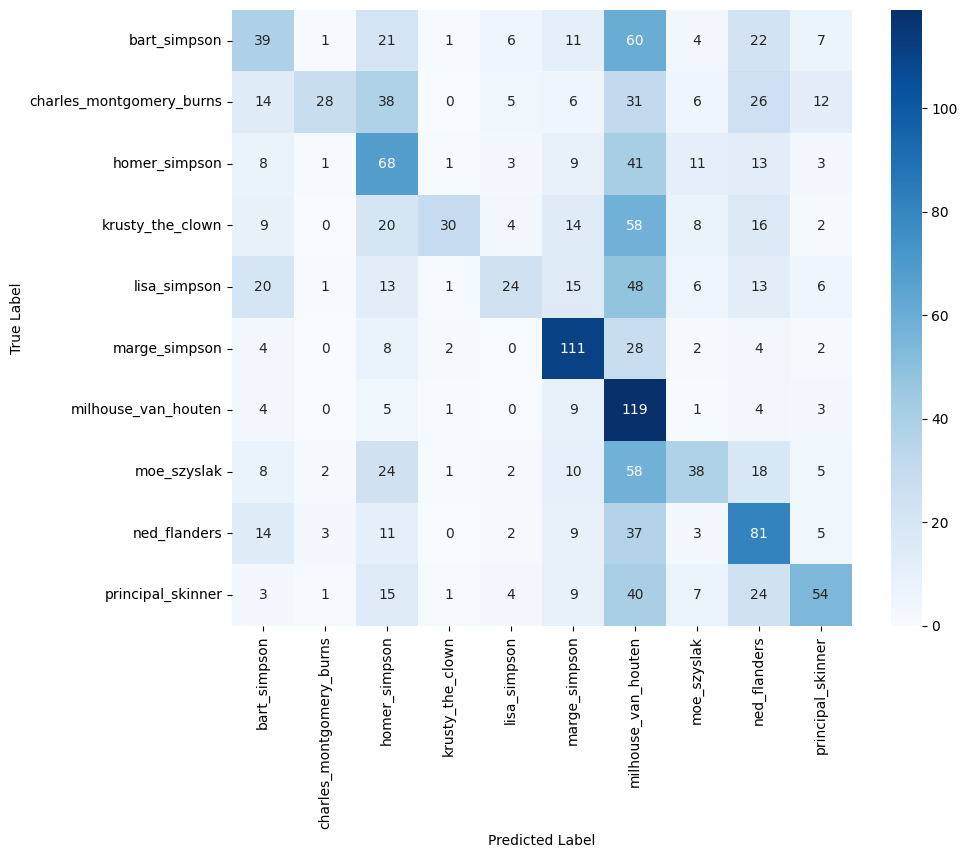

In [36]:
print("Training RGB perceptron demo...")
n_features = X_train_rgb.shape[1]
model_rgb = MultiClassPerceptron(n_classes=10, n_features=n_features, learning_rate=0.01)
history_rgb = train_perceptron(model_rgb, X_train_rgb, y_train_rgb, X_val_rgb, y_val_rgb, epochs=20) # epochs = 5

print("\nValidation performance (RGB subset):")
evaluate_model(model_rgb, X_val_rgb, y_val_rgb)
